In [1]:
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.datasets import mnist
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout
from tensorflow.keras.utils import to_categorical

In [2]:
# 加载数据集
(X_train, y_train), (X_test, y_test) = mnist.load_data()

In [3]:
# 数据预处理
# 归一化（0-1范围）
X_train = X_train.astype('float32') / 255
X_test = X_test.astype('float32') / 255

# 调整数据维度（添加通道维度）
X_train = X_train.reshape(-1, 28, 28, 1)
X_test = X_test.reshape(-1, 28, 28, 1)

# 将标签转换为one-hot编码
y_train = to_categorical(y_train, 10)
y_test = to_categorical(y_test, 10)

In [4]:
# 创建CNN模型
model = Sequential()

# 卷积层1
model.add(Conv2D(32, (3, 3), activation='relu', input_shape=(28, 28, 1)))
model.add(MaxPooling2D((2, 2)))
model.add(Dropout(0.25))

# 卷积层2
model.add(Conv2D(64, (3, 3), activation='relu'))
model.add(MaxPooling2D((2, 2)))
model.add(Dropout(0.25))

# 全连接层
model.add(Flatten())
model.add(Dense(128, activation='relu'))
model.add(Dropout(0.5))
model.add(Dense(10, activation='softmax'))  # 输出层

f:\python\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [5]:
# 编译模型
model.compile(optimizer='adam',
              loss='categorical_crossentropy',
              metrics=['accuracy'])

In [6]:
# 训练模型
history = model.fit(X_train, y_train,
                    epochs=10,
                    batch_size=128,
                    validation_split=0.2)

Epoch 1/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 20s 35ms/step - accuracy: 0.7374 - loss: 0.8042 - val_accuracy: 0.9728 - val_loss: 0.0951
Epoch 2/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 10s 28ms/step - accuracy: 0.9541 - loss: 0.1500 - val_accuracy: 0.9809 - val_loss: 0.0659
Epoch 3/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - accuracy: 0.9679 - loss: 0.1056 - val_accuracy: 0.9849 - val_loss: 0.0514
Epoch 4/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 10s 28ms/step - accuracy: 0.9734 - loss: 0.0879 - val_accuracy: 0.9862 - val_loss: 0.0467
Epoch 5/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - accuracy: 0.9756 - loss: 0.0792 - val_accuracy: 0.9879 - val_loss: 0.0414
Epoch 6/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 11s 30ms/step - accuracy: 0.9805 - loss: 0.0661 - val_accuracy: 0.9887 - val_loss: 0.0375
Epoch 7/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 12s 32ms/step - accuracy: 0.9816 - loss: 0.0608 - val_accuracy: 0.9893 - val_loss: 0.0380
Epoch 8/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 11s 30ms/step - accuracy: 0.9831 - loss: 0.0564 - 

In [7]:
# 评估模型
test_loss, test_acc = model.evaluate(X_test, y_test)
print(f'\n测试准确率: {test_acc:.4f}')

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9868 - loss: 0.0381

测试准确率: 0.9892


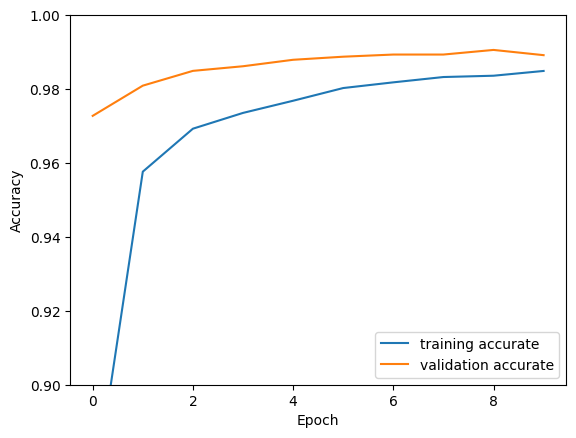

In [8]:
# 可视化训练过程
plt.plot(history.history['accuracy'], label='training accurate')
plt.plot(history.history['val_accuracy'], label='validation accurate')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.ylim([0.9, 1])
plt.legend(loc='lower right')
plt.show()

In [9]:
# 进行预测示例
def predict_example(index):
    plt.imshow(X_test[index].reshape(28, 28), cmap='gray')
    plt.show()
    prediction = model.predict(X_test[index].reshape(1, 28, 28, 1))
    print(f"Prediction: {np.argmax(prediction)}")

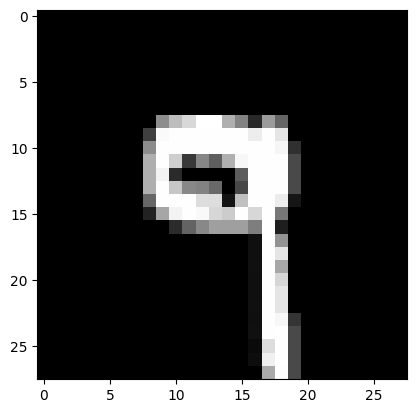

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 80ms/step
Prediction: 9


In [10]:
# 调用示例预测
predict_example(6000)